## SECTION A — Learning Mission

# Day 01 — Environment, Jupyter & Your First Market Data

| | |
|---|---|
| **Course** | PyTrades — ALX-style Algorithmic Trading Programme |
| **Video** | *Algorithmic Trading Python for Beginners - FULL TUTORIAL* — QuantProgram |
| **Today's segment** | **00:00–13:00** (Intro → Anaconda → yfinance → Jupyter → numpy/pandas → downloading stock data) |
| **Video link** | https://www.youtube.com/watch?v=GDMkkmkJigw&t=0s |
| **Estimated study time** | **2–3 hours** (≈15 min watching · ≈30 min guided · ≈75 min independent · ≈30 min project) |
| **Prerequisites** | A computer where you can install software. No prior trading knowledge. Basic file/folder literacy. |
| **Expected deliverable** | **P0.1:** a validated close-price CSV + labelled price chart + 5-bullet data-quality report (Section F), with Section G passing |

## Learning objectives — by the end of today you will be able to

1. **Set up and verify** a Python environment for this course and prove, *in code*, which versions of Python/pandas/numpy you are running.
2. **Distinguish** a *function*, a *method* and a *library*, and use `Shift+Tab` / `help()` to inspect an unfamiliar function instead of guessing.
3. **Obtain** daily OHLCV market data for an explicit date range (live via `yfinance` when online; from the bundled sample when offline) as a `pandas.DataFrame` with a `DatetimeIndex`.
4. **Inspect** that frame — shape, columns, dtypes, date range, missing values — and explain what each OHLCV column means.
5. **Implement** `validate_ohlcv(df)` that returns `True` for a clean frame and raises `ValueError` with a *specific* message for an empty, unsorted, duplicated or non-positive-priced frame.
6. **Explain** why "the code ran" is not the same as "the data is trustworthy".

> ⚠️ **Education only.** Nothing in this course is financial advice. Today you are
> learning data handling — no strategy you meet in this programme is a recommendation to trade.

> 🧭 **ALX rule for this notebook:** type the exercises yourself. Watching the video
> is item 1 of 7 on today's checklist (Section I). It is not the finish line.

---
## SECTION B — Video Learning  ·  00:00–13:00

**Before you press play, write down your best guess at these four questions.**
You will check them in Section H. Do not look them up first — a wrong guess you
correct yourself is worth more than a copied answer.

1. What is the difference between installing a *library* (e.g. `yfinance`) and *importing* it?
2. A Jupyter code cell shows `In [7]` but the cell above it shows `In [3]`. Why should that make you suspicious of the results?
3. `yf.download("SPY", start="2020-01-01", end="2020-12-31")` — what comes back: a number, a list, or a table? What are its rows and columns?
4. The first row of downloaded data is dated **2020-01-02**, not 2020-01-01. Is data missing?

### Watch for (official chapters inside today's segment)

| Time | Chapter | Pay attention to |
|---|---|---|
| 00:00 | Intro | The "zero to hero" promise — today is only the first 13 minutes of it |
| 00:55 | Installation of Anaconda | *That* an environment is installed, not the clicks themselves |
| 01:50 | Installing Yfinance | `pip install yfinance` happens in a **terminal**, outside the notebook |
| 02:40 | Working with Jupyter Notebook | Cells, `Shift+Enter`, `print`, `abs`, `Shift+Tab` for help |
| 06:58 | numpy and pandas and other libraries | `import ... as ...` aliases: `np`, `pd` |
| 07:50 | Downloading stock data | Ticker + start + end → a DataFrame. Notice the columns he gets |
| 12:00 | Working with data | The first things he does *after* the download — that habit is today's real lesson |

Fallback links (start at the right second):
[00:00](https://www.youtube.com/watch?v=GDMkkmkJigw&t=0s) ·
[02:40 Jupyter](https://www.youtube.com/watch?v=GDMkkmkJigw&t=160s) ·
[07:50 download](https://www.youtube.com/watch?v=GDMkkmkJigw&t=470s) ·
[stop at 13:00](https://www.youtube.com/watch?v=GDMkkmkJigw&t=780s)

*Embedding needs internet and a notebook frontend that allows iframes. If the
player below is blank, use the links above — the rest of today works offline.*

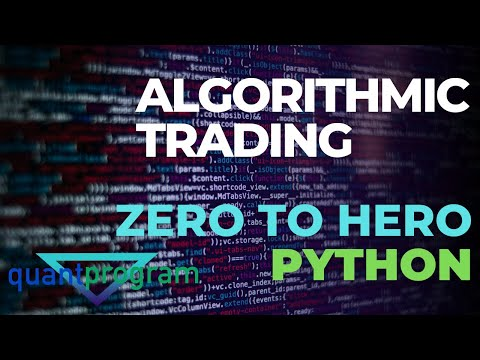

Fallback: https://www.youtube.com/watch?v=GDMkkmkJigw&t=0s  (watch to 13:00)


In [1]:
# ▶️ SECTION B (code) — the video, embedded. Segment: 00:00 - 13:00 (stop at 13:00 today)
from IPython.display import YouTubeVideo, display

display(
    YouTubeVideo(
        "GDMkkmkJigw",   # Algorithmic Trading Python for Beginners - FULL TUTORIAL (QuantProgram)
        start=0,         # 00:00
        end=780,         # 13:00 - "Read and writing Data" is Day 02
        width=800,
        height=450,
    )
)
print("Fallback: https://www.youtube.com/watch?v=GDMkkmkJigw&t=0s  (watch to 13:00)")

**After watching, before touching Section C:** in the cell below, write a
3-bullet summary of the video *in your own words*, plus one thing the presenter
did that you could not yet reproduce from memory. (Markdown cell — double-click to edit.)

✍️ **My 3-bullet summary (edit me):**

-
-
-

**One thing I cannot yet reproduce from memory:**

-

---
## SECTION C — Concept Notes (read actively: predict, then run)

### C1. Environment ≠ notebook ≠ library — three different layers

| Layer | What it is | Day-01 example | Typical failure |
|---|---|---|---|
| **Environment** | A Python interpreter + installed packages | Anaconda (video) or `.venv` | `ModuleNotFoundError: No module named 'yfinance'` |
| **Kernel** | The running Python process behind *this* notebook | The "Python 3" shown top-right | Notebook uses a different environment than your terminal |
| **Library** | Reusable code you `import` | `pandas`, `numpy`, `yfinance` | Installing in the terminal but never importing — or the reverse |

**Install once (terminal), import every session (notebook).** The video installs
with Anaconda's terminal (`01:50`). `pip install -r ../requirements.txt` inside a
virtual environment is the equivalent modern route [programme addition] — either
is acceptable here, but you must be able to say *which* environment your kernel uses.

### C2. Function vs method (the video introduces the first; pandas lives on the second)

- A **function** stands alone: `print(x)`, `abs(-5)`, `len(df)`. You *pass* data to it.
- A **method** is called *on* an object with a dot: `df.head()`, `df["Close"].mean()`.
  The object itself is the data. If you write `head(df)` you will get `NameError` —
  that error is pandas telling you "that's a method, not a function".
- A **library** is a collection of functions/classes: `import pandas as pd` gives you `pd.DataFrame`, `pd.read_csv`, …

Stuck on what something does? The video's `Shift+Tab` trick, or `help(pd.read_csv)` —
**read the first three lines of the docstring before searching the web.**

### C3. What a download actually returns: OHLCV bars

One row = one trading day for one ticker. Columns:

| Column | Meaning | Watch out |
|---|---|---|
| `Open` / `High` / `Low` / `Close` | First, highest, lowest, last traded price that day | `High >= max(Open, Close)` and `Low <= min(Open, Close)` in sane data |
| `Adj Close` | Close adjusted for splits/dividends | Don't mix `Close` and `Adj Close` in one calculation — pick one and say which |
| `Volume` | Shares/contracts traded | `0` volume on a trading day is a data-quality smell |

The **index** is the date (`DatetimeIndex`). Markets close on weekends/holidays,
so gaps between Friday and Monday are *normal* — a missing Wednesday is not.

### C4. The 2022 video vs today's `yfinance` ⚠️

Recent `yfinance` versions may return **MultiIndex columns** like `("Close", "SPY")`
and treat adjustment differently from the video. If your columns don't match the
video's, you have not made a mistake — the library changed. Today's defence, and
the habit for the whole course: **inspect first** (`df.columns`, `df.shape`,
`type(df["Close"])`), *then* adapt. Exercise 2 makes you handle both shapes.

### C5. Notebook state: the invisible bug factory

Cells run in the order *you executed them*, not the order they appear. A notebook
that only works after random clicking is not reproducible. Professional standard
for this course: **Kernel → Restart & Run All** must succeed before you submit a day.

### C6. Why validation before analysis?

Every later day (returns, moving averages, backtests) silently assumes: dates sorted,
no duplicates, prices positive, `Close` actually present. Violate one assumption
and you don't get an error — you get a *wrong strategy that looks profitable*.
Section E makes those assumptions executable code.

In [2]:
# C (setup) — run this first, every session. If an import fails, fix the ENVIRONMENT (Section C1),
# do not delete the import.  One-time install (uncomment in a fresh env):
# %pip install -r ../requirements.txt

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| numpy:", np.__version__)
print("cwd    :", Path.cwd())
print("kernel environment executable:", sys.executable)

python : 3.13.5
pandas : 3.1.0 | numpy: 2.5.4
cwd    : /home/kai/PyTrades/notebooks
kernel environment executable: /home/kai/PyTrades/pytrades/bin/python


In [3]:
# C (data) — load today's data. Preference order:
#   1) the bundled sample CSV (deterministic, offline)  2) regenerate identical synthetic data
# The live yfinance download is a separate, optional cell further down.

def find_demo_csv():
    rel = Path("data") / "sample" / "demo_ohlcv.csv"
    here = Path.cwd()
    for base in [here, *here.parents]:
        for cand in (base / rel, base.parent / rel):
            if cand.exists():
                return cand
    return None


def make_demo_ohlcv(n=252, seed=42):
    '''Regenerate the SAME synthetic data as tools/generate_sample_data.py (seed 42).'''
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range("2020-01-02", periods=n, freq="B")
    log_returns = rng.normal(loc=0.0004, scale=0.011, size=n)
    close = 100.0 * np.exp(np.cumsum(log_returns))
    open_ = np.empty(n); open_[0] = 100.0
    open_[1:] = close[:-1] * np.exp(rng.normal(0, 0.002, size=n - 1))
    intraday = np.abs(rng.normal(0, 0.004, size=n))
    frame = pd.DataFrame({
        "Open": np.round(open_, 4),
        "High": np.round(np.maximum(open_, close) * (1 + intraday), 4),
        "Low": np.round(np.minimum(open_, close) * (1 - intraday), 4),
        "Close": np.round(close, 4),
        "Adj Close": np.round(close, 4),
        "Volume": rng.integers(800_000, 3_000_000, size=n),
    }, index=dates)
    frame.index.name = "Date"
    return frame


csv_path = find_demo_csv()
if csv_path is not None:
    df = pd.read_csv(csv_path, parse_dates=["Date"], index_col="Date")
    print("loaded bundled sample:", csv_path)
else:
    df = make_demo_ohlcv()
    print("bundled CSV not found - regenerated identical synthetic data in memory")

print("shape (rows, cols):", df.shape)
print("index type        :", type(df.index).__name__)
df.head()

loaded bundled sample: /home/kai/PyTrades/data/sample/demo_ohlcv.csv
shape (rows, cols): (252, 6)
index type        : DatetimeIndex


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2020-01-02,100.0000,100.9792,99.3990,100.3759,100.3759,974780
2020-01-03,100.7235,101.9179,98.0967,99.2739,99.2739,1595379
2020-01-06,99.0781,100.3545,98.8627,100.1368,100.1368,2415106
2020-01-07,100.0877,102.1987,99.1187,101.2187,101.2187,2588950
2020-01-08,101.3762,101.5525,98.9368,99.1092,99.1092,1126666


---
## SECTION D — Guided Exploration (predict → run → modify → record)

For each experiment: **(1)** write your prediction in the ✍️ cell, **(2)** run the
code, **(3)** do the *Modify* task, **(4)** record what actually happened.
Being wrong in a prediction is the mechanism — skipping it removes the learning.

### Experiment D1 — Function or method?

**Predict:** which of these raise an error, and which error? `len(df)` ·
`df.head(2)` · `head(df)` · `df["Close"].mean()` · `mean(df["Close"])`

✍️ **D1 prediction (edit me):** 

In [4]:
# D1 - run, compare with your prediction, then uncomment ONE broken line at a time and read the error.
print("len(df)              ->", len(df), "         (function: data passed in)")
print("df['Close'].mean()   ->", round(float(df["Close"].mean()), 4), " (method: called ON the Series)")
print("type(df['Close'])    ->", type(df["Close"]).__name__)
#head(df)                 # TODO(modify): uncomment, run, write the error name below. Then re-comment it.
# mean(df["Close"])        # TODO(modify): same. Why does np.mean(df["Close"]) work but bare mean(...) not?

len(df)              -> 252          (function: data passed in)
df['Close'].mean()   -> 100.1581  (method: called ON the Series)
type(df['Close'])    -> Series


✍️ **D1 observed (edit me):** the error for `head(df)` was `___name___Error`, which tells me `head` is a ____method___, not a __function____.

**Why it works this way:** methods belong to the object's class (`DataFrame`/`Series`).
That is also why `Shift+Tab` on `df.head(` shows *DataFrame* docs. File this away:
Day 11 you will write a class and give it methods of your own.

### Experiment D2 — The index is not decoration

**Predict:** `df` is sorted oldest→newest. What does `df.iloc[0]` return vs
`df.loc["2020-01-02"]`? After `df.sort_index(ascending=False)`, which of the two
*changes what it returns*? Which one is therefore dangerous for "first price" logic?

✍️ **D2 prediction (edit me):** 

In [5]:
# D2 - position (.iloc) vs label (.loc)
print("first ROW by position:\n", df.iloc[0][["Close"]].to_dict(), "on", df.index[0].date())
print("row LABELLED 2020-01-02:", float(df.loc["2020-01-02", "Close"]))

reversed_df = df.sort_index(ascending=False)
print("\nafter reversing: .iloc[0] is now", reversed_df.index[0].date(),
      "- but .loc['2020-01-02'] is still", float(reversed_df.loc["2020-01-02", "Close"]))

# TODO(modify): slice June 2020 by label and print its first/last dates. Why must the index be sorted for this to work?
june = df.loc["2020-06-01":"2020-06-30"]
print("June rows:", len(june), "|", june.index.min().date(), "->", june.index.max().date())

first ROW by position:
 {'Close': 100.3759} on 2020-01-02
row LABELLED 2020-01-02: 100.3759

after reversing: .iloc[0] is now 2020-12-18 - but .loc['2020-01-02'] is still 100.3759
June rows: 22 | 2020-06-01 -> 2020-06-30


✍️ **D2 observed (edit me):** `.iloc[0]` means "___the first row in the dataframe____", `.loc[...]` means "___the item which index is that____".
Code that wants the *earliest* price must therefore ___sort indexes____ before trusting position 0.
(Exercise 3 is a bug built on exactly this.)

### Experiment D3 — When `df["Close"]` is not a Series (modern yfinance shape)

**Predict:** in the video, `df["Close"]` is a 1-D `Series`. Below is the *shape*
newer `yfinance` can return. What will `type(demo_mi["Close"])` be, and what
will `.mean()` on it return — one number, or something else?

✍️ **D3 prediction (edit me):** 

In [6]:
# D3 - simulated modern-yfinance columns: ("Close", "DEMO"), ("Volume", "DEMO")
mi_cols = pd.MultiIndex.from_tuples([("Close", "DEMO"), ("Volume", "DEMO")])
demo_mi = pd.DataFrame(
    [[100.0, 1000], [101.5, 1100], [99.0, 900]],
    index=pd.to_datetime(["2021-01-04", "2021-01-05", "2021-01-06"]),
    columns=mi_cols,
)
print("columns          :", list(demo_mi.columns))
print("type(demo_mi['Close']) ->", type(demo_mi["Close"]).__name__, "| shape:", demo_mi["Close"].shape)
print("one-column slice ->", type(demo_mi["Close"].iloc[:, 0]).__name__,
      "| values:", list(demo_mi["Close"].iloc[:, 0]))
# TODO(modify): print demo_mi["Close"].mean() and demo_mi["Close"].iloc[:, 0].mean(). Which type is each?

columns          : [('Close', 'DEMO'), ('Volume', 'DEMO')]
type(demo_mi['Close']) -> DataFrame | shape: (3, 1)
one-column slice -> Series | values: [100.0, 101.5, 99.0]


✍️ **D3 observed (edit me):** with MultiIndex columns, `df["Close"]` gives a _______, so code written
for the video can silently produce the wrong *type*. The robust fix is to _______.
You will implement that fix yourself in Exercise 2 — it is tested on both shapes.

---
### Optional live download (ungraded — needs internet)

The video's centrepiece. Run it if you are online; if it fails, **that is a
finding, not a failure**: record the error and continue with the bundled data.
Compare the columns you *actually* get with the video's (Section C4).

In [7]:
# D4 (OPTIONAL, online only) - the video's live download, made failure-proof.
# Graded work never depends on this cell: networks rate-limit and library shapes drift.
try:
    import yfinance as yf
    live = yf.download("SPY", start="2020-01-01", end="2020-02-01", auto_adjust=False, progress=False)
    if live is None or len(live) == 0:
        print("yfinance returned no rows (offline? rate-limited?). Record this and continue with `df`.")
    else:
        print("live shape:", live.shape)
        print("live columns:", list(live.columns))   # <- compare with the 2022 video!
        print(live.head(3))
except Exception as exc:  # deliberate: today you practise REPORTING a data failure, not crashing on one
    print(f"live download unavailable ({type(exc).__name__}: {exc}) - continuing offline with bundled `df`.")

live shape: (21, 6)
live columns: [('Adj Close', 'SPY'), ('Close', 'SPY'), ('High', 'SPY'), ('Low', 'SPY'), ('Open', 'SPY'), ('Volume', 'SPY')]
Price        Adj Close       Close        High         Low        Open  \
Ticker             SPY         SPY         SPY         SPY         SPY   
Date                                                                     
2020-01-02  295.391754  324.869995  324.890015  322.529999  323.540009   
2020-01-03  293.155029  322.410004  323.640015  321.100006  321.160004   
2020-01-06  294.273407  323.640015  323.730011  320.359985  320.489990   

Price         Volume  
Ticker           SPY  
Date                  
2020-01-02  59151200  
2020-01-03  77709700  
2020-01-06  55653900  


/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index

---
## SECTION E — Independent Practice (no video, no copy-paste)

**Rules:** implement from the docstrings. Docs are allowed
([pandas](https://pandas.pydata.org/docs/), `help(...)`, `Shift+Tab`); the video is not.
Use hints in order — Hint 1 first, and only open the next after a genuine attempt.
Every function below is tested in Section G on data you have not seen.

### Exercise 1 — Basic application: `summarise_ohlcv`

Summarise a price frame the way Section C3 says a professional inspects it first.

In [8]:
def summarise_ohlcv(df):
    '''
    Return a summary dict for an OHLCV DataFrame with EXACTLY these keys:
        n_rows        : int          - number of rows
        start         : Timestamp    - earliest index value  (use the index, not row 0's position)
        end           : Timestamp    - latest index value
        columns       : list[str]    - column names in order
        missing_close : int          - count of NaN values in the 'Close' column
    Raise ValueError if df is empty.
    '''
    # TODO: implement from the spec above. No printing - RETURN the dict.
    if df.empty:
        raise ValueError
    dct = {}
    dct["n_rows"] =  df.shape[0]
    dct["start"] =  df.index.min()
    dct["end"] =  df.index.max()
    dct['columns'] = list(df.columns)
    dct["missing_close"] = df['Close'].isna().sum()

    return dct
    



<details><summary>Hint 1 — concept</summary>Everything you need lives on `df.index`, `df.columns` and `df["Close"]`. "Earliest" is a property of the values, not of the current row order.</details>
<details><summary>Hint 2 — approach</summary>`df.index.min()` / `.max()` survive unsorted frames; `df.index[0]` does not. Count missing with a boolean mask summed, or an `isna` method.</details>
<details><summary>Hint 3 — implementation clue</summary>`int(df["Close"].isna().sum())` — note the `int(...)`: tests compare types, and a numpy int is not the same citizen everywhere.</details>

### Exercise 2 — Modification: `extract_close` that survives both column shapes

The video's code assumes `df["Close"]` is a Series. Yours must not (Experiment D3).

In [9]:
def extract_close(df):
    '''
    Return the Close prices as a 1-D float pd.Series named 'Close', preserving df's index.

    Must work for BOTH shapes:
      (a) flat columns:                [..., 'Close', ...]
      (b) MultiIndex columns (level 0): [..., ('Close', '<TICKER>'), ...]
    Raise KeyError if there is no Close column in either shape.
    Do not modify df in place.
    '''
    # TODO
    df = df.copy()
    try:
        df.columns = df.columns.get_level_values(0)
    except Exception:
        pass
    finally:
        if "Close" not in df.columns:
            raise KeyError
        return df['Close']


In [10]:
close = extract_close(df)
close

Date
2020-01-02    100.3759
2020-01-03     99.2739
2020-01-06    100.1368
2020-01-07    101.2187
2020-01-08     99.1092
                ...   
2020-12-14     94.7757
2020-12-15     97.8924
2020-12-16     96.6776
2020-12-17     96.3253
2020-12-18     96.7266
Name: Close, Length: 252, dtype: float64

<details><summary>Hint 1 — concept</summary>First ask what kind of columns you have: `isinstance(df.columns, pd.MultiIndex)`. The two shapes need different extractions.</details>
<details><summary>Hint 2 — approach</summary>For shape (b), `df["Close"]` gives a one-column DataFrame; D3 showed one way to get its single column positionally. For shape (a), `df["Close"]` is already a Series.</details>
<details><summary>Hint 3 — implementation clue</summary>Whatever path you took, finish with `.astype(float)` and set `.name = "Close"` on a *copy* — `df["Close"].iloc[:, 0]` for (b). Guard the missing case explicitly so the error is `KeyError`, not a confusing `IndexError`.</details>

### Exercise 3 — Debugging: the "first and last price" that lies

The function below was written by a learner who skipped Experiment D2.
**Do not edit it yet.** First, run the diagnosis cell and write down *three*
distinct defects (there are at least three) — what breaks, and *why*.
Then implement the corrected version underneath.

In [11]:
# --- BUGGY CODE (study it; do not fix it in place) ---
def first_and_last_close_buggy(df):
    close = df["Close"]          # defect candidates live on this line...
    first = close[0]             # ...and this one...
    last = close[-1]             # ...and this one. Plus an assumption about ORDER.
    return first, last


# Diagnosis runner - read each error/message carefully:
toy = df.head(5)
for label, frame in [("normal order", toy), ("reversed order", toy.sort_index(ascending=False))]:
    try:
        print(label, "->", first_and_last_close_buggy(frame))
    except Exception as exc:
        print(label, "-> RAISED", type(exc).__name__, ":", exc)

normal order -> RAISED KeyError : 0
reversed order -> RAISED KeyError : 0


✍️ **My diagnosis (edit me — required, this is graded in Section H):**

1. Defect 1: … because the key close was misspelt
2. Defect 2: … because didt use iloc to get the values at porition
3. Defect 3: … because supposed to use lioc

In [12]:
def first_and_last_close(df):
    '''
    Return (first_close, last_close) as floats, BY DATE (earliest and latest),
    regardless of the row order df arrives in. Raise ValueError if df is empty.
    Must work when the Close column arrives in either shape from Exercise 2
    (reusing your own extract_close is encouraged - professionals compose).
    '''
    if df.empty:
        raise ValueError
    close = extract_close(df)
    close = close.sort_index(ascending=True)
    return float(close.iloc[0]), float(close.iloc[-1])


<details><summary>Hint 1 — concept</summary>"First" in finance means earliest *date*, not smallest *position*. Sort by index, then positions become trustworthy.</details>
<details><summary>Hint 2 — approach</summary>`close.sort_index()`, then `.iloc[0]` / `.iloc[-1]` are *positional* and safe on a DatetimeIndex. `close[-1]` is label-based and is not.</details>
<details><summary>Hint 3 — implementation clue</summary>Column names are case-sensitive: the data says `Close`, the bug says `close`. Convert to `float(...)` on return.</details>

### Exercise 4 — Independent implementation: `validate_ohlcv` (today's core deliverable)

This is Section C6 as code. Every later day will call a descendant of this function.

In [13]:
def validate_ohlcv(df, required_columns=("Open", "High", "Low", "Close", "Volume")):
    '''
    Validate an OHLCV frame. Return True if valid; otherwise RAISE ValueError
    whose message names the specific problem (tests check the exception type,
    a human will check that the message is genuinely informative).

    Reject (ValueError) when ANY of these hold:
      - df is not a DataFrame, or is empty
      - the index is not a DatetimeIndex
      - the index is not sorted ascending (monotonic increasing)
      - the index contains duplicate timestamps
      - any of required_columns is missing (flat columns case)
      - 'Close' contains NaN, or any Close value <= 0
    '''
    # TODO: check in an order that never crashes with the WRONG exception type.
    # e.g. check 'is it a DataFrame / non-empty' before touching df['Close'].
    if not isinstance(df, pd.DataFrame) or df.empty or not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("check df")
    elif not df.index.is_monotonic_increasing:
        raise ValueError("Df should be sorted ascending")
    elif df.index.has_duplicates:
        raise ValueError("Index must not contain duplicates")
    elif not all(col in df.columns for col in required_columns):
        raise ValueError("Missing required columns")
    elif df['Close'].isna().sum() > 0 or df["Close"].min() <= 0:
        raise ValueError("Invalid close values")
    else:
        return True
    

<details><summary>Hint 1 — concept</summary>Each bullet maps to a pandas question: `isinstance`, `df.empty`, `isinstance(df.index, pd.DatetimeIndex)`, `df.index.is_monotonic_increasing`, `df.index.has_duplicates`, `set(required) - set(df.columns)`, `df["Close"].isna().any()`, `(df["Close"] <= 0).any()`.</details>
<details><summary>Hint 2 — approach</summary>Order matters for *which* error surfaces first. A test with an empty frame must get "empty", not a KeyError about Close. Structure: type/emptiness → index checks → column checks → value checks.</details>
<details><summary>Hint 3 — implementation clue</summary>Write each check as `if <bad>: raise ValueError("...specific...")`. End with `return True`. Note: a monotonic check alone does NOT catch duplicates — equal neighbours are still "increasing" in pandas' sense. That trap is tested.</details>

### Exercise 5 — Transfer: coverage across *several* tickers (not in the video)

Day 05 downloads five stocks at once. The professional first question is never
"what's the return?" — it is "does each series actually cover the period I think
it does?" Build that check now, for a situation the video has not shown you.

In [14]:
def compare_coverage(data_by_ticker):
    '''
    data_by_ticker: dict like {"AAA": df_a, "BBB": df_b} (insertion order arbitrary)

    Return a pd.DataFrame INDEXED BY ticker (sorted A->Z), with columns:
        n_rows        int
        start         Timestamp (earliest date for that ticker)
        end           Timestamp (latest date)
        missing_close int (NaNs in that ticker's Close)
    An empty dict returns an empty DataFrame with exactly those columns.
    Reuse summarise_ohlcv - do not duplicate its logic.
    '''
    # TODO
    df = pd.DataFrame(columns=['n_rows', 'start', 'end', 'missing_close'])
    for ticker, data in data_by_ticker.items():
        df.loc[ticker] = [data.shape[0], data.index.min(), data.index.max(), data['Close'].isna().sum()]
    return df.sort_index(ascending=True)


In [15]:
ds = yf.download('aapl', start='2026-01-01')
type(ds.columns)

/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/kai/PyTrades/pytrades/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_

pandas.MultiIndex

<details><summary>Hint 1 — concept</summary>This is Exercise 1 applied repeatedly, then assembled. Composition beats copy-paste.</details>
<details><summary>Hint 2 — approach</summary>Build a dict of rows `{ticker: {"n_rows": ..., ...}}`, then one `pd.DataFrame.from_dict(..., orient="index")` — or collect per-ticker dicts and index them. Sort the *index* at the end.</details>
<details><summary>Hint 3 — implementation clue</summary>For the empty-dict edge case, `pd.DataFrame(columns=[...])` gives the right shape. Tests use tickers inserted in reverse alphabetical order specifically to catch a missing sort.</details>

---
## SECTION F — Daily Mini-Project · P0.1 Reproducible Market-Data Intake Report

**Problem (the real one):** every strategy in this course is worthless if its
input data is silently broken. Today you build the intake step a desk would
insist on before any analysis: *validate → extract → persist → summarise → plot*.

### Specification — implement `build_day01_report(df, output_csv)`

| | Requirement |
|---|---|
| **Input** | An OHLCV `DataFrame` (either column shape from Ex. 2 must not crash it — validate the flat parts you rely on, extract via your Ex. 2) and an output CSV path (`str` or `Path`) |
| **Behaviour** | 1) take a **sorted-by-date copy** first (unsorted input is *accepted* here — `validate_ohlcv` alone would reject it, order matters) · 2) if columns are flat, `validate_ohlcv` the sorted copy; if MultiIndex, extract via `extract_close` and check that Close is non-NaN and positive · 3) extract Close via `extract_close` · 4) create parent folders if needed · 5) write CSV with header `Date,Close` · 6) return the summary dict below |
| **Returns** | `{"n_rows": int, "start": Timestamp, "end": Timestamp, "first_close": float, "last_close": float, "pct_change_total": float}` where `pct_change_total = last/first - 1` |
| **Constraints** | No global variables; no modifying the caller's `df`; must work on unseen dates/values; re-runnable (idempotent) |
| **Then** | Run it on today's `df` → `data/processed/day01_close.csv`, plot the closing price (labelled axes + title), and write the 5-bullet quality report cell |

### Acceptance criteria (all must hold)

- [ ] Section G project checks pass on a frame you have never seen, in a temp folder
- [ ] The written CSV round-trips: reading it back gives the same dates and closes
- [ ] Your chart's title/axes let a stranger know *what, when, which series* — unattributed lines fail review
- [ ] Your 5 bullets each make a *checkable* claim (rows, range, gaps, missing, extremes) — "the data looks good" is not a claim

### Test cases you should anticipate (Section G uses these ideas with different numbers)

Unsorted input · MultiIndex columns · output path in a folder that doesn't exist yet ·
a frame where `last < first` (negative `pct_change_total`) · being called twice in a row.

In [24]:
# SECTION F - implement the project function here (compose Exercises 1-4; invent as little as possible)
from pathlib import Path as _Path  # already imported above; harmless to reaffirm the tool you need

def build_day01_report(df, output_csv):
    '''See Section F specification. Returns the summary dict, writes Date,Close CSV.'''
    # TODO
    df = df.sort_index(ascending=True)
    if isinstance(df.columns, pd.MultiIndex):
        closes = extract_close(df)
        if closes.isna().sum() > 0 or closes.min() <= 0:
            raise ValueError("invalid closes")
    else:
        validate_ohlcv(df)
        closes = extract_close(df)
    _Path(output_csv).parent.mkdir(parents=True, exist_ok=True)
    closes.index.name = "Date"
    closes = closes.rename("Close")
    closes.to_csv(output_csv)

    returns = {"n_rows": closes.size, "start": closes.index[0], "end": closes.index[-1], "first_close": closes.iloc[0], "last_close": closes.iloc[-1]}
    returns["pct_change_total"] = returns["last_close"] / returns["first_close"] - 1
    return returns
    
    


    

In [23]:
from pathlib import Path

p = Path("../data/processed/day01_close.csv")

if p.is_dir():
    p.rmdir()  # Works only if the directory is empty

report: {'n_rows': 252, 'start': Timestamp('2020-01-02 00:00:00'), 'end': Timestamp('2020-12-18 00:00:00'), 'first_close': np.float64(100.3759), 'last_close': np.float64(96.7266), 'pct_change_total': np.float64(-0.03635633653098003)}


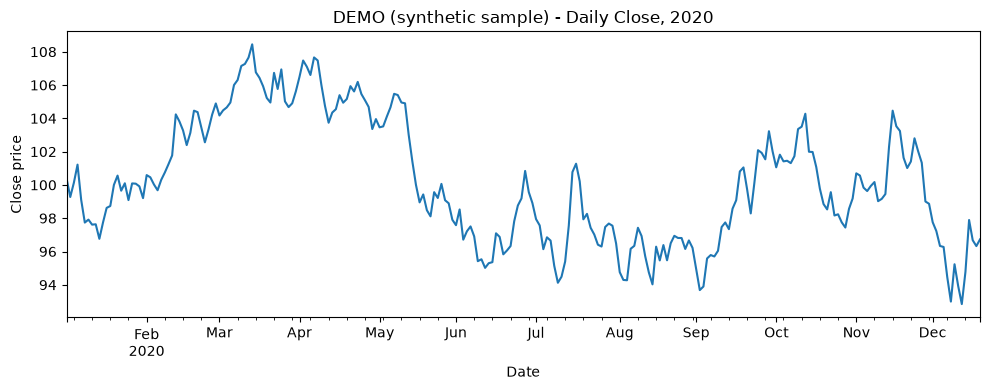

In [25]:
# SECTION F (apply) - run YOUR function on today's data, then chart the result.
# Until build_day01_report is implemented this prints None - that None is your to-do list, not an error.
report = build_day01_report(df, _Path("..") / "data" / "processed" / "day01_close.csv") \
    if Path.cwd().name == "notebooks" else build_day01_report(df, Path("data") / "processed" / "day01_close.csv")
print("report:", report)

# Chart (guided - labels are done properly here ON PURPOSE: imitate this standard all course)
ax = df["Close"].plot(figsize=(10, 4), title="DEMO (synthetic sample) - Daily Close, 2020")
ax.set_xlabel("Date"); ax.set_ylabel("Close price")
plt.tight_layout(); plt.show()

✍️ **P0.1 data-quality report — 5 checkable bullets (edit me, replace every … with a number you verified):**

1. Coverage: … rows from … to … (business days only? how did you check?)
2. Missing values: Close has … NaNs; the other columns …
3. Ordering/duplicates: index sorted ascending = …; duplicate dates = …
4. Sanity: min Close = …, max Close = …; any non-positive prices? …
5. Verdict: this data is / is not fit for Day 02 analysis because …

---
## SECTION G — Automated Assessment (run me; iterate until green)

Visible checks below report **PASS/FAIL per behaviour** and never stop at the first
failure, so this notebook always runs top-to-bottom. Two warnings:

- These are the *visible* checks. Review uses **unseen variants** — different dates,
  values, row orders and dirtier frames (see `assessments/README.md`). Hard-coding and
  copying the video both fail those by construction.
- A wall of FAILs *before* you attempt Section E/F is the expected starting state.

In [26]:
# SECTION G - assessment harness + visible checks (do not edit the harness)
import tempfile

RESULTS = []
def check(name, fn):
    try:
        ok = bool(fn()); msg = ""
    except Exception as exc:
        ok = False; msg = f"{type(exc).__name__}: {exc}"
    RESULTS.append(ok)
    print(("PASS" if ok else "FAIL"), "-", name, (("| " + msg) if msg else ""))

def raises(exc_type, fn):
    try:
        fn()
    except exc_type:
        return True
    except Exception:
        return False
    return False

def _small():
    idx = pd.to_datetime(["2021-01-04", "2021-01-05", "2021-01-06"])
    return pd.DataFrame({"Open": [10., 11, 12], "High": [11., 12, 13], "Low": [9., 10, 11],
                         "Close": [10.5, 11.5, 12.5], "Volume": [100, 200, 300]}, index=idx)

def _multi(frame):
    out = frame.copy()
    out.columns = pd.MultiIndex.from_tuples([(c, "ZZZ") for c in frame.columns])
    return out

s = _small()
# Exercise 1
check("Ex1 keys & values", lambda: summarise_ohlcv(s) == {
    "n_rows": 3, "start": pd.Timestamp("2021-01-04"), "end": pd.Timestamp("2021-01-06"),
    "columns": ["Open", "High", "Low", "Close", "Volume"], "missing_close": 0})
check("Ex1 counts a NaN close", lambda: summarise_ohlcv(
    s.assign(Close=[10.5, np.nan, 12.5]))["missing_close"] == 1)
check("Ex1 empty -> ValueError", lambda: raises(ValueError, lambda: summarise_ohlcv(s.iloc[0:0])))

# Exercise 2
check("Ex2 flat -> float Series named Close", lambda: (
    lambda r: isinstance(r, pd.Series) and r.name == "Close" and r.dtype.kind == "f"
    and list(r) == [10.5, 11.5, 12.5] and list(r.index) == list(s.index))(extract_close(s)))
check("Ex2 MultiIndex -> same Series", lambda: list(extract_close(_multi(s))) == [10.5, 11.5, 12.5])
check("Ex2 no Close -> KeyError", lambda: raises(KeyError, lambda: extract_close(s.drop(columns=["Close"]))))

# Exercise 3
check("Ex3 chronological on SHUFFLED rows", lambda: first_and_last_close(
    s.iloc[[2, 0, 1]]) == (10.5, 12.5))
check("Ex3 empty -> ValueError", lambda: raises(ValueError, lambda: first_and_last_close(s.iloc[0:0])))

# Exercise 4
check("Ex4 clean frame -> True", lambda: validate_ohlcv(s) is True)
check("Ex4 unsorted -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(s.iloc[[1, 0, 2]])))
check("Ex4 duplicate date -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(
    pd.concat([s, s.iloc[[0]]]).sort_index())))
check("Ex4 negative close -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(
    s.assign(Close=[10.5, -1.0, 12.5]))))
check("Ex4 NaN close -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(
    s.assign(Close=[10.5, np.nan, 12.5]))))
check("Ex4 missing column -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(
    s.drop(columns=["Volume"]))))
check("Ex4 non-date index -> ValueError", lambda: raises(ValueError, lambda: validate_ohlcv(s.reset_index(drop=True))))
check("Ex4 empty -> ValueError (not KeyError)", lambda: raises(ValueError, lambda: validate_ohlcv(s.iloc[0:0])))

# Exercise 5
_a = s.assign(Close=[1.0, np.nan, 3.0])
check("Ex5 sorted tickers + values", lambda: (
    lambda r: list(r.index) == ["AAA", "BBB"] and int(r.loc["AAA", "missing_close"]) == 1
    and int(r.loc["BBB", "n_rows"]) == 3 and r.loc["BBB", "start"] == pd.Timestamp("2021-01-04")
)(compare_coverage({"BBB": s, "AAA": _a})))
check("Ex5 empty dict -> empty frame, right columns", lambda: (
    lambda r: isinstance(r, pd.DataFrame) and len(r) == 0
    and list(r.columns) == ["n_rows", "start", "end", "missing_close"])(compare_coverage({})))

# Section F project
def _project_ok():
    with tempfile.TemporaryDirectory() as tmp:
        out = Path(tmp) / "nested" / "close.csv"          # parent does not exist yet - on purpose
        rep = build_day01_report(s.iloc[[2, 0, 1]], out)  # unsorted input - on purpose
        back = pd.read_csv(out, parse_dates=["Date"], index_col="Date")
        return (out.exists() and rep["n_rows"] == 3 and rep["first_close"] == 10.5
                and rep["last_close"] == 12.5 and abs(rep["pct_change_total"] - (12.5 / 10.5 - 1)) < 1e-12
                and list(back["Close"]) == [10.5, 11.5, 12.5])
check("F  project: report dict + CSV round-trip (unsorted in, nested path)", _project_ok)

print(f"\nSCORE: {sum(RESULTS)}/{len(RESULTS)} visible checks passing")
print("Green here is necessary, not sufficient: review re-tests on unseen data (assessments/README.md).")

PASS - Ex1 keys & values 
PASS - Ex1 counts a NaN close 
PASS - Ex1 empty -> ValueError 
PASS - Ex2 flat -> float Series named Close 
PASS - Ex2 MultiIndex -> same Series 
PASS - Ex2 no Close -> KeyError 
PASS - Ex3 chronological on SHUFFLED rows 
PASS - Ex3 empty -> ValueError 
PASS - Ex4 clean frame -> True 
PASS - Ex4 unsorted -> ValueError 
PASS - Ex4 duplicate date -> ValueError 
PASS - Ex4 negative close -> ValueError 
PASS - Ex4 NaN close -> ValueError 
PASS - Ex4 missing column -> ValueError 
PASS - Ex4 non-date index -> ValueError 
PASS - Ex4 empty -> ValueError (not KeyError) 
PASS - Ex5 sorted tickers + values 
PASS - Ex5 empty dict -> empty frame, right columns 
PASS - F  project: report dict + CSV round-trip (unsorted in, nested path) 

SCORE: 19/19 visible checks passing
Green here is necessary, not sufficient: review re-tests on unseen data (assessments/README.md).


---
## SECTION H — Knowledge Check (write answers below each question; no code unless asked)

**H1 — Predict the output** (then verify in a scratch cell *after* answering):
`type(df["Close"])`, `type(df[["Close"]])`, `len(df.loc["2020-06-01":"2020-06-30"])` on an *unsorted* frame — which one misbehaves, and how?

✍️

**H2 — Explain why:** `close[-1]` is a bug on a DatetimeIndex but `close.iloc[-1]` is not. What two different lookup systems are involved?

✍️

**H3 — Explain your implementation:** in 3–5 sentences, explain to a non-programmer what `validate_ohlcv` guarantees and what it *cannot* guarantee (name one way data can pass your checks and still be wrong — e.g. a wrong-but-positive price).

✍️

**H4 — What-if:** `yfinance` tomorrow renames `Adj Close` and returns tz-aware indexes. Which of today's functions survive unchanged? Which one *should* fail loudly, and why is loud failure the desired behaviour there?

✍️

**H5 — Debug the claim:** a classmate says "my download has gaps — 2020-01-04 and 2020-01-05 are missing, the feed is broken". Refute or confirm using a calendar, in two sentences — then state what "missing data" would *actually* look like in daily bars.

✍️

**H6 — Design:** Day 02 saves this frame to CSV and reloads it. Predict the single most likely way that round-trip silently corrupts today's work, and the check you would add to catch it.

✍️

---
## SECTION I — Reflection & Retrieval Practice

### What I learned (3 bullets, concepts not activities — edit me)
-
-
-

### What I can now implement *without the video* (be brutally specific)
-
-

### What I still find difficult / my open questions (bring these back — Day 02 adapts to them)
-
-

### Retrieval practice — baseline (Day 01 has no earlier days, so these probe the video + Python foundations; from Day 02 this section tests *earlier notebooks* at widening intervals)

Answer from memory, *then* check:
1. Installing a package happens once in the _______; importing happens every _______ in the _______.
2. `df.head()` is a _______ on a DataFrame; `len(df)` is a _______. Write one more example of each.
3. A daily OHLCV frame's index should be a _______, sorted _______, with no _______.
4. Why is a Friday→Monday gap *not* missing data, and how would you detect a genuinely missing trading day?
5. Your kernel shows `In [12]` directly above `In [4]`. State the risk in one sentence and the fix in three words.

### Reimplementation challenge (from memory — close Section E first)

Implement `validate_close_from_memory(close)` below: return `True` for a non-empty,
NaN-free, all-positive float Series with a sorted DatetimeIndex; raise `ValueError`
otherwise. If you had to peek, say so in "still difficult" — that honesty is data, not shame.

In [ ]:
# SECTION I - reimplementation challenge (from memory)
def validate_close_from_memory(close):
    '''True if: non-empty Series, DatetimeIndex sorted ascending, no NaN, all values > 0.
    Else raise ValueError. (Self-check cell below is gentle on purpose - review is not.)'''
    # TODO (from memory)
    pass


# gentle self-check (prints rather than asserts):
try:
    ok = validate_close_from_memory(df["Close"]) is True
except Exception as exc:
    ok = False; print("self-check raised:", type(exc).__name__, exc)
print("reimplementation self-check on today's Close:", "PASS" if ok else "not yet - revisit Exercise 4")

reimplementation self-check on today's Close: not yet - revisit Exercise 4


### ✅ Completion checklist — Day 01 is done when ALL are true

- [ ] Watched **00:00–13:00** and wrote the Section B summary in my own words
- [ ] Completed D1–D3 including *written predictions made before running*
- [ ] Exercises 1–5 implemented by me (hints used are fine; copied code is not)
- [ ] Exercise 3's three-defect diagnosis written in my own words
- [ ] **P0.1** done: CSV written, labelled chart, 5-bullet checkable quality report
- [ ] Section G fully green **after Kernel → Restart & Run All**
- [ ] Section H answered + reimplementation challenge attempted honestly

**Send back:** your Section G score, your H3 explanation, and your "still difficult"
list. Day 02 (*Working with data: read/write, select & segregate, 13:00–23:00*)
is generated from — and adapted to — exactly that.